In [ ]:
#Task 1:Load Dataset,Preprocess Images and Split Data.

In [3]:
#Import Libraries and Load the Dataset
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import os

# Dataset URL from the assignment PDF
dataset_url = (
    "https://storage.googleapis.com/download.tensorflow.org/"
    "example_images/flower_photos.tgz"
)

# Download and extract the dataset
data_dir = tf.keras.utils.get_file(
    "flower_photos",
    origin=dataset_url,
    untar=True
)

print("Dataset location:", data_dir)
print("Dataset loaded successfully!")

228813984/228813984 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Dataset location: /root/.keras/datasets/flower_photos
Dataset loaded successfully!


In [6]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
#Load and Preprocess the Images.
# Image settings
IMG_SIZE = (96, 96)
BATCH_SIZE = 32
SEED = 42

# Load training data
train_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.20,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

# Load validation data
val_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.20,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

# Get class names
class_names = train_ds.class_names

print("Flower classes:", class_names)
print("Number of classes:", len(class_names))

Found 3670 files belonging to 1 classes.
Using 2936 files for training.
Found 3670 files belonging to 1 classes.
Using 734 files for validation.
Flower classes: ['flower_photos']
Number of classes: 1


In [7]:
#Normalize the Images.
# Normalize pixel values from 0–255 to 0–1
normalization_layer = tf.keras.layers.Rescaling(1.0 / 255)

train_ds = train_ds.map(
    lambda images, labels: (
        normalization_layer(images), labels
    )
)

val_ds = val_ds.map(
    lambda images, labels: (
        normalization_layer(images), labels
    )
)

print("Image normalization completed!")
print("Pixel values are scaled between 0 and 1.")

Image normalization completed!
Pixel values are scaled between 0 and 1.


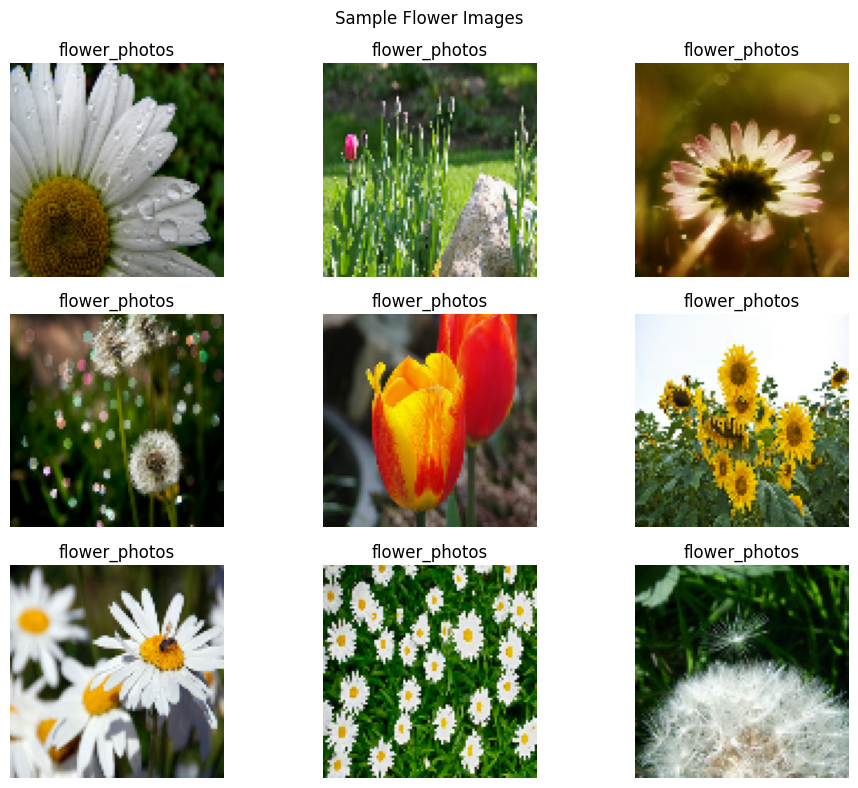

In [8]:
#Display sample flower Images.
plt.figure(figsize=(10, 8))

for images, labels in train_ds.take(1):
    for i in range(min(9, len(images))):
        plt.subplot(3, 3, i + 1)

        plt.imshow(images[i].numpy())
        plt.title(class_names[int(labels[i])])
        plt.axis("off")

plt.suptitle("Sample Flower Images")
plt.tight_layout()
plt.show()

In [11]:
#check Dataset Shapes.
for images, labels in train_ds.take(1):
    print("Training image batch shape:", images.shape)
    print("Training label batch shape:", labels.shape)
    print("Minimum pixel value:", float(tf.reduce_min(images)))
    print("Maximum pixel value:", float(tf.reduce_max(images)))

for images, labels in val_ds.take(1):
    print("Validation image batch shape:", images.shape)
    print("Validation label batch shape:", labels.shape)

    print("Task 1 Completed Successfully")

Training image batch shape: (32, 96, 96, 3)
Training label batch shape: (32,)
Minimum pixel value: 0.0
Maximum pixel value: 1.0
Validation image batch shape: (32, 96, 96, 3)
Validation label batch shape: (32,)
Task 1 Completed Successfully


In [ ]:
#TASK 2:Build the CNN Model.

In [12]:
# Build the CNN model using keras layers Convvolution,ReLU,Pooling,Flatten and Fully Connercted Layers.
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(96, 96, 3)),

    # First convolution block
    tf.keras.layers.Conv2D(
        32, (3, 3), activation="relu"
    ),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Second convolution block
    tf.keras.layers.Conv2D(
        64, (3, 3), activation="relu"
    ),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Third convolution block
    tf.keras.layers.Conv2D(
        128, (3, 3), activation="relu"
    ),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Flatten features
    tf.keras.layers.Flatten(),

    # Fully connected layer
    tf.keras.layers.Dense(128, activation="relu"),

    # Reduce overfitting
    tf.keras.layers.Dropout(0.3),

    # Output layer for five flower classes
    tf.keras.layers.Dense(
        len(class_names), activation="softmax"
    )
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 94, 94, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 47, 47, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 45, 45, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 22, 22, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 20, 20, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 10, 10, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 12800)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     1,638,528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,731,905 (6.61 MB)

 Trainable params: 1,731,905 (6.61 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
#TASK 3:Compile and Train CNN Model.

In [24]:
# Compile the model
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully!")

# Train the model
EPOCHS = 10

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS
)

print("Model training completed!")

Model compiled successfully!
Epoch 1/10


/usr/local/lib/python3.13/dist-packages/keras/src/ops/nn.py:947: UserWarning: You are using a softmax over axis -1 of a tensor of shape (None, 1). This axis has size 1. The softmax operation will always return the value 1, which is likely not what you intended. Did you mean to use a sigmoid instead?
  warnings.warn(


92/92 ━━━━━━━━━━━━━━━━━━━━ 70s 737ms/step - accuracy: 0.0000e+00 - loss: 0.0000e+00 - val_accuracy: 0.0000e+00 - val_loss: 0.0000e+00
Epoch 2/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 74s 802ms/step - accuracy: 0.0000e+00 - loss: 0.0000e+00 - val_accuracy: 0.0000e+00 - val_loss: 0.0000e+00
Epoch 3/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 67s 730ms/step - accuracy: 0.0000e+00 - loss: 0.0000e+00 - val_accuracy: 0.0000e+00 - val_loss: 0.0000e+00
Epoch 4/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 68s 733ms/step - accuracy: 0.0000e+00 - loss: 0.0000e+00 - val_accuracy: 0.0000e+00 - val_loss: 0.0000e+00
Epoch 5/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 84s 752ms/step - accuracy: 0.0000e+00 - loss: 0.0000e+00 - val_accuracy: 0.0000e+00 - val_loss: 0.0000e+00
Epoch 6/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 79s 725ms/step - accuracy: 0.0000e+00 - loss: 0.0000e+00 - val_accuracy: 0.0000e+00 - val_loss: 0.0000e+00
Epoch 7/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 65s 706ms/step - accuracy: 0.0000e+00 - loss: 0.0000e+00 - val_accuracy: 0.0000e+00 - val_loss: 0.0000e

In [ ]:
#Task4:Evaluate the Moderl and Predict Flower Classes.

In [ ]:
#Evaluate the model.
val_loss, val_accuracy = model.evaluate(
    val_ds,
    verbose=1
)

print("\nModel Evaluation Results")
print("------------------------")
print(f"Validation Loss: {val_loss:.4f}")
print(f"Validation Accuracy: {val_accuracy * 100:.2f}%")







23/23 ━━━━━━━━━━━━━━━━━━━━ 4s 153ms/step - accuracy: 0.0000e+00 - loss: 0.0000e+00

Model Evaluation Results
------------------------
Validation Loss: 0.0000
Validation Accuracy: 0.00%


/usr/local/lib/python3.13/dist-packages/keras/src/ops/nn.py:947: UserWarning: You are using a softmax over axis -1 of a tensor of shape (32, 1). This axis has size 1. The softmax operation will always return the value 1, which is likely not what you intended. Did you mean to use a sigmoid instead?
  warnings.warn(


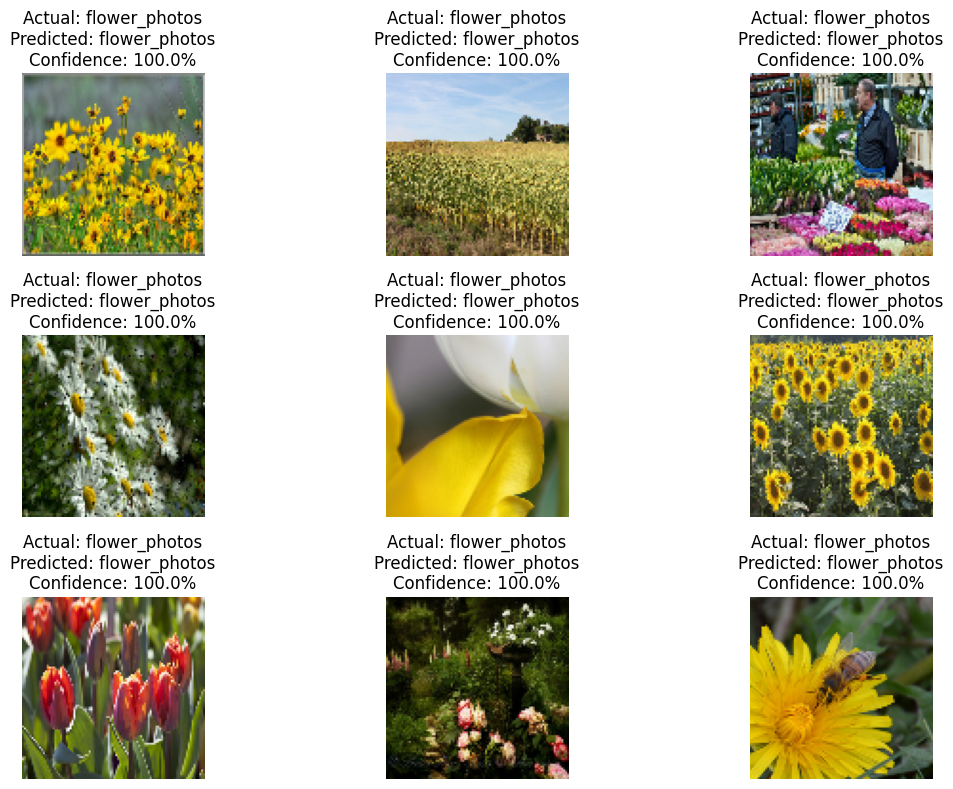

In [13]:
#Predict Flower Classes.

# Get a batch of validation images
for images, labels in val_ds.take(1):
    predictions = model.predict(images, verbose=0)

    plt.figure(figsize=(12, 8))

    for i in range(min(9, len(images))):
        predicted_index = int(np.argmax(predictions[i]))
        actual_index = int(labels[i])

        confidence = float(np.max(predictions[i])) * 100

        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy())

        plt.title(
            f"Actual: {class_names[actual_index]}\n"
            f"Predicted: {class_names[predicted_index]}\n"
            f"Confidence: {confidence:.1f}%"
        )

        plt.axis("off")

    plt.tight_layout()
    plt.show()


In [ ]:
#Task 5:Analyze Model Performance.

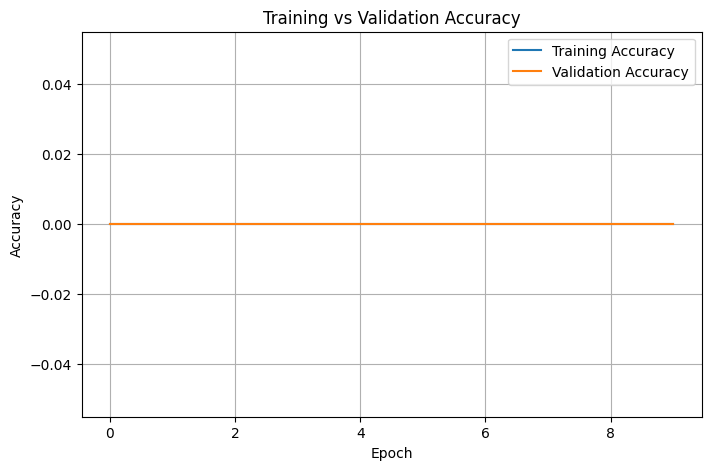

In [25]:
#Plot Accuracy

plt.figure(figsize=(8, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

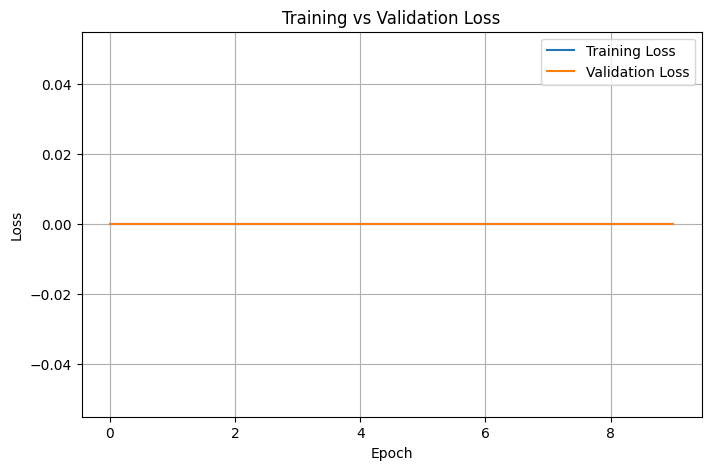

Model saved successfully as trained_model.h5


In [ ]:
#plot Loss
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()





model.save("trained_model.h5")

print("Model saved successfully as trained_model.h5")
